### **Projet de prediction du prix de maisons**
Ce projet va nous permettre de predire le prix de maisons sur base de certaines formes de caracteristiques

#### **1. Importations de librairies**

##### **Description des librairies**

In [2]:
# 1. Numpy : est une bibliotheque pour les calculs numeriques en Python. 
# Elle fournit des structures de données et des fonctions 
# pour effectuer des opérations mathématiques sur des tableaux multidimensionnels (ndarray). 
# Numpy est largement utilisé dans le domaine de l'apprentissage automatique, 
# de la science des données et de l'analyse numérique.

# 2. Matplotlib : est une bibliothèque de visualisation de données en Python.
# Elle permet de créer des graphiques, des diagrammes et des visualisations interactives.

# 3. Pandas : est une bibliothèque de manipulation et d'analyse de données en Python.
# Elle fournit des structures de données flexibles, telles que les DataFrames,
# qui sont largement utilisées pour le traitement et l'analyse de données.

# 4. Scikit-learn : est une bibliothèque d'apprentissage automatique en Python.
# Elle fournit des outils pour la classification, la régression, le clustering et d'autres tâches

# 5. Seaborn : est une bibliothèque de visualisation de données basée sur Matplotlib.
# Elle fournit une interface de haut niveau pour créer des visualisations statistiques attrayantes et informatives.

In [3]:
# installation des autres librairies
# %pip install matplotlib pandas scikit-learn seaborn

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.model_selection import learning_curve
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error


# pour gerer les warnings
import warnings
warnings.filterwarnings("ignore")


#### **2. Chargement des donnees**

In [5]:
df = pd.read_csv("data/data.csv")

In [6]:
df.head(5)

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


In [7]:
df.info

<bound method DataFrame.info of                      date         price  bedrooms  bathrooms  sqft_living  \
0     2014-05-02 00:00:00  3.130000e+05       3.0       1.50         1340   
1     2014-05-02 00:00:00  2.384000e+06       5.0       2.50         3650   
2     2014-05-02 00:00:00  3.420000e+05       3.0       2.00         1930   
3     2014-05-02 00:00:00  4.200000e+05       3.0       2.25         2000   
4     2014-05-02 00:00:00  5.500000e+05       4.0       2.50         1940   
...                   ...           ...       ...        ...          ...   
4595  2014-07-09 00:00:00  3.081667e+05       3.0       1.75         1510   
4596  2014-07-09 00:00:00  5.343333e+05       3.0       2.50         1460   
4597  2014-07-09 00:00:00  4.169042e+05       3.0       2.50         3010   
4598  2014-07-10 00:00:00  2.034000e+05       4.0       2.00         2090   
4599  2014-07-10 00:00:00  2.206000e+05       3.0       2.50         1490   

      sqft_lot  floors  waterfront  view  c

#### **3. Analyse de données**

In [8]:
df.isna()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4595,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4596,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4597,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4598,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [9]:
df.isna().sum()

date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
street           0
city             0
statezip         0
country          0
dtype: int64

In [10]:
# apercu de la dimension de notre dataset

print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

Nombre de lignes : 4600
Nombre de colonnes : 18


In [11]:
print(df.isnull().sum())

date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
street           0
city             0
statezip         0
country          0
dtype: int64


In [12]:
# Affichage des statistiques descriptives

df.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated
count,4.600000e+03,4600.000000,4600.000000,4600.000000,4.600000e+03,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000
mean,5.519630e+05,3.400870,2.160815,2139.346957,1.485252e+04,1.512065,0.007174,0.240652,3.451739,1827.265435,312.081522,1970.786304,808.608261
std,5.638347e+05,0.908848,0.783781,963.206916,3.588444e+04,0.538288,0.084404,0.778405,0.677230,862.168977,464.137228,29.731848,979.414536
min,0.000000e+00,0.000000,0.000000,370.000000,6.380000e+02,1.000000,0.000000,0.000000,1.000000,370.000000,0.000000,1900.000000,0.000000
25%,3.228750e+05,3.000000,1.750000,1460.000000,5.000750e+03,1.000000,0.000000,0.000000,3.000000,1190.000000,0.000000,1951.000000,0.000000
50%,4.609435e+05,3.000000,2.250000,1980.000000,7.683000e+03,1.500000,0.000000,0.000000,3.000000,1590.000000,0.000000,1976.000000,0.000000
75%,6.549625e+05,4.000000,2.500000,2620.000000,1.100125e+04,2.000000,0.000000,0.000000,4.000000,2300.000000,610.000000,1997.000000,1999.000000
max,2.659000e+07,9.000000,8.000000,13540.000000,1.074218e+06,3.500000,1.000000,4.000000,5.000000,9410.000000,4820.000000,2014.000000,2014.000000


In [13]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
price,4600.0,551962.988473,563834.702547,0.0,322875.00,460943.461539,654962.50,26590000.0
bedrooms,4600.0,3.400870,0.908848,0.0,3.00,3.000000,4.00,9.0
bathrooms,4600.0,2.160815,0.783781,0.0,1.75,2.250000,2.50,8.0
sqft_living,4600.0,2139.346957,963.206916,370.0,1460.00,1980.000000,2620.00,13540.0
sqft_lot,4600.0,14852.516087,35884.436145,638.0,5000.75,7683.000000,11001.25,1074218.0
floors,4600.0,1.512065,0.538288,1.0,1.00,1.500000,2.00,3.5
waterfront,4600.0,0.007174,0.084404,0.0,0.00,0.000000,0.00,1.0
view,4600.0,0.240652,0.778405,0.0,0.00,0.000000,0.00,4.0
condition,4600.0,3.451739,0.677230,1.0,3.00,3.000000,4.00,5.0
sqft_above,4600.0,1827.265435,862.168977,370.0,1190.00,1590.000000,2300.00,9410.0


In [14]:
# Examen de la variable cible (target variable) : "price"
df['price'].describe()

count    4.600000e+03
mean     5.519630e+05
std      5.638347e+05
min      0.000000e+00
25%      3.228750e+05
50%      4.609435e+05
75%      6.549625e+05
max      2.659000e+07
Name: price, dtype: float64

array([[<Axes: title={'center': 'price'}>]], dtype=object)

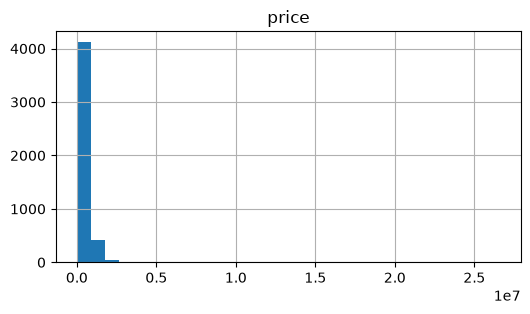

In [15]:
df[['price']].hist(bins=30, figsize=(6, 3))

#### **4. Pretraitement de données**

In [16]:
# Supprimer les valeurs nulles du DataFrame df et créer un nouveau DataFrame df_clean
df_clean = df.dropna()

In [17]:
# Copie du dataframe
df_clean = df_clean.copy()

In [18]:
df.columns

Index(['date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot',
       'floors', 'waterfront', 'view', 'condition', 'sqft_above',
       'sqft_basement', 'yr_built', 'yr_renovated', 'street', 'city',
       'statezip', 'country'],
      dtype='str')

In [19]:
# Suppression des valeurs ou les prix sont inferieurs a 0 ou egaux a 0
df_clean = df_clean[df_clean['price'] > 0]

# df_clean[df_clean['price'] <= 0].count()

# Ingenierie des caracteristiques (Feature Engineering)
# calcul de l'age de la maison sur base de son annee de construction

df_clean['age'] = 2014 - df_clean['yr_built']

# Selection des caracteristiques (features) numeriques pour la regression lineaire
df_clean_features = df_clean[['bedrooms', 
                              'bathrooms', 'sqft_living', 
                              'sqft_lot', 'floors', 'waterfront', 
                              'view', 'condition', 'sqft_above', 
                              'sqft_basement', 'yr_built', 
                              'yr_renovated', 'age']]

# traitement de la variable categorielle "city" en utilisant la technique de codage one-hot (one-hot encoding)
df_clean_city = pd.get_dummies(df, columns=['city'], drop_first=True)

# Assemblage du dataset final pour la regression lineaire
y_final = df_clean['price']
x_final = pd.concat([df_clean_features, df_clean_city], axis=1)   

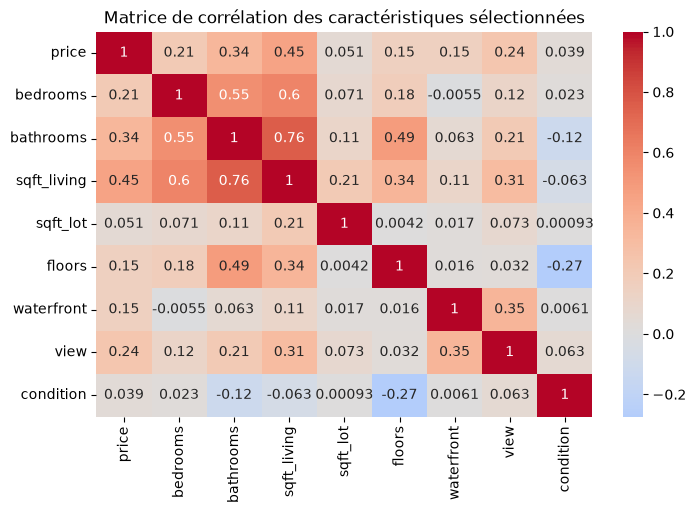

In [20]:
# Creation de la matrice de correlation

colonnes_analyse = ['price', 'bedrooms', 'bathrooms', 
                    'sqft_living', 'sqft_lot',
                    'floors', 'waterfront', 'view', 'condition']

# On calcule la matrice de correlation pour les colonnes d'analyse
correlation_matrix = df_clean[colonnes_analyse].corr()

# correlation_matrix
#On affiche la matrice de correlation sous forme de carte thermique (heatmap)
plt.figure(figsize=(8, 5))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Matrice de corrélation des caractéristiques sélectionnées')
plt.show()

#### **4. Division en train/test**

In [21]:
# Division en train et test

X = df_clean[colonnes_analyse]
y = df_clean['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, 
                        test_size=0.2, random_state=42)   

#### **5. Creation des modeles de machine learning**

##### **5.1. Regression lineaire classique**

In [22]:
# creation des modeles de machine learning pour la regression lineaire
model_rl = LinearRegression()
# Entrainer le modele
model_rl.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](9,)","[ 1.,-0., 0.,..., 0.,-0., 0.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](9,)","['price','bedrooms','bathrooms',...,'waterfront','view','condition']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.596e-07
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(6)


##### **5.2. Regression Ridge (regression regularisée)**

In [23]:
# creation du modele de la regression ridge 
model_ridge = make_pipeline(StandardScaler(), Ridge(alpha=10))
# entrainer le modele
model_ridge.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['price','bedrooms','bathrooms',...,'waterfront','view','condition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


#### **6. Visualisation de la courbe d'entrainement**

In [24]:
# on verifie si la colonne cible s'est glissée dans les features du dataset final

print("Colonnes du dataset final :", x_final.columns)
print("Colonne cible :", y_final.name)

Colonnes du dataset final : Index(['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors',
       'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement',
       'yr_built', 'yr_renovated', 'age', 'date', 'price', 'bedrooms',
       'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view',
       'condition', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated',
       'street', 'statezip', 'country', 'city_Auburn',
       'city_Beaux Arts Village', 'city_Bellevue', 'city_Black Diamond',
       'city_Bothell', 'city_Burien', 'city_Carnation', 'city_Clyde Hill',
       'city_Covington', 'city_Des Moines', 'city_Duvall', 'city_Enumclaw',
       'city_Fall City', 'city_Federal Way', 'city_Inglewood-Finn Hill',
       'city_Issaquah', 'city_Kenmore', 'city_Kent', 'city_Kirkland',
       'city_Lake Forest Park', 'city_Maple Valley', 'city_Medina',
       'city_Mercer Island', 'city_Milton', 'city_Newcastle',
       'city_Normandy Park', 'city_North Bend', '

In [25]:
print("price" in x_final.columns)

True


In [26]:
# enlever price de x_final pour eviter la fuite de données (data leakage)
x_final = x_final.drop(columns=['price'])

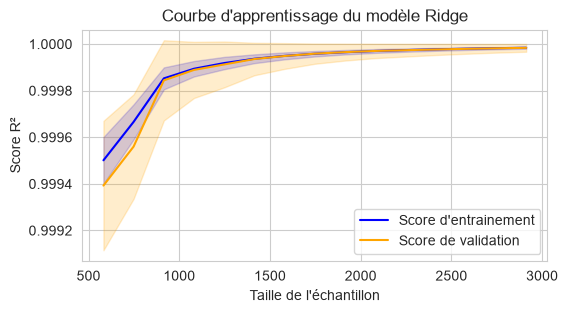

In [27]:
# visualisation de la courbe d'entrainement (learning curve)
# Calculer les scores d'entrainement et de validation croisée pour différentes tailles d'échantillons

train_sizes, train_scores, val_scores = learning_curve(model_ridge, X_train, 
                                                       y_train, cv=5, 
                                                       scoring='r2', 
                                                       train_sizes=np.linspace(0.2, 1.0, 15))

# calcul de moyenne et de l'écart type des scores d'entrainement et de validation
train_scores_mean = np.mean(train_scores, axis=1)
train_scores_std = np.std(train_scores, axis=1)
val_scores_mean = np.mean(val_scores, axis=1)
val_scores_std = np.std(val_scores, axis=1)

# tracer de la courbe d'entrainement
plt.figure(figsize=(6, 3))
sns.set_style("whitegrid")
plt.plot(train_sizes, train_scores_mean, label='Score d\'entrainement', color='blue')
plt.fill_between(train_sizes, train_scores_mean - train_scores_std, train_scores_mean + train_scores_std, alpha=0.2, color='blue')
plt.plot(train_sizes, val_scores_mean, label='Score de validation', color='orange')
plt.fill_between(train_sizes, val_scores_mean - val_scores_std, val_scores_mean + val_scores_std, alpha=0.2, color='orange')
plt.xlabel('Taille de l\'échantillon')
plt.ylabel('Score R²')
plt.title('Courbe d\'apprentissage du modèle Ridge')
plt.legend()
plt.show()

#### **7. Evaluation de nos modeles**

In [28]:
# evaluation de nos modeles de regression lineaire classique ainsi que ridge

mae_rl = mean_absolute_error(y_test, model_rl.predict(X_test))
mae_ridge = mean_absolute_error(y_test, model_ridge.predict(X_test))

print("MAE du modèle de régression linéaire :", mae_rl)
print("MAE du modèle Ridge :", mae_ridge)

mse_rl = mean_squared_error(y_test, model_rl.predict(X_test))
mse_ridge = mean_squared_error(y_test, model_ridge.predict(X_test))

print("MSE du modèle de régression linéaire :", mse_rl)
print("MSE du modèle Ridge :", mse_ridge)

rmse_rl = np.sqrt(mse_rl)
rmse_ridge = np.sqrt(mse_ridge)

print("RMSE du modèle de régression linéaire :", rmse_rl)
print("RMSE du modèle Ridge :", rmse_ridge)

r2_rl = r2_score(y_test, model_rl.predict(X_test))
r2_ridge = r2_score(y_test, model_ridge.predict(X_test))

print("R² du modèle de régression linéaire :", r2_rl)
print("R² du modèle Ridge :", r2_ridge)

MAE du modèle de régression linéaire : 2.9602924409873466e-08
MAE du modèle Ridge : 559.8220161748418
MSE du modèle de régression linéaire : 1.3795349984527423e-15
MSE du modèle Ridge : 703653.8784186168
RMSE du modèle de régression linéaire : 3.714209200425768e-08
RMSE du modèle Ridge : 838.8407944411244
R² du modèle de régression linéaire : 1.0
R² du modèle Ridge : 0.9999952702021204
